# 03 — Baseline expected-points model: walk-forward backtest

`src/baseline_model.py` fits a ridge regression on the lagged panel features and forecasts each gameweek, training **only on earlier gameweeks**.
The benchmark is the naive estimate most managers use: mean points over the last five gameweeks.

The question is the same as for any trading strategy: **does it beat the benchmark out-of-sample, and consistently?**

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd

from baseline_model import add_period, coefficients, compare

results = pd.read_csv("../data/backtest_results.csv")
compare(results).round(3)

,model,naive,diff,t_stat,model_wins
mae,1.084,1.111,-0.027,-4.090,0.743
rmse,1.990,2.169,-0.179,-17.243,1.000
ic,0.688,0.696,-0.007,-1.398,0.314
ic_starters,0.274,0.139,0.135,9.450,0.943
top20_pts,4.560,3.824,0.736,4.393,0.743


- **`ic_starters`** is the number that matters for decisions: how well the forecast ranks players who will actually play. The model roughly doubles it.
- **`top20_pts`** is the average points of the 20 highest-forecast players each gameweek, the return of a long-only top-20 portfolio.
- **`ic`** over *all* players is a tie. Both methods easily separate players who play from those who don't.

## 1. Equity curve of the top-20 portfolio

Cumulative points from holding each method's top 20 forecasts every gameweek. A widening gap means the edge holds up over time.

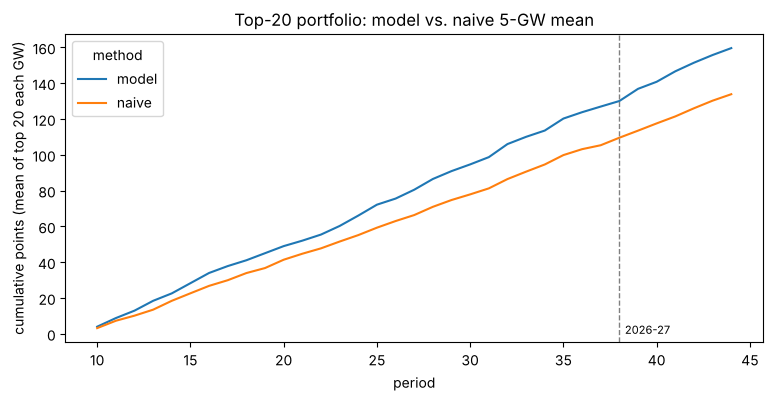

In [2]:
wide = results.pivot(index="period", columns="method", values="top20_pts")
labels = results.drop_duplicates("period").set_index("period")
ax = wide.cumsum().plot(figsize=(9, 4))
ax.set_ylabel("cumulative points (mean of top 20 each GW)")
ax.set_title("Top-20 portfolio: model vs. naive 5-GW mean")
season_start = labels.index[labels["season"].ne(labels["season"].shift())][1:]
for p in season_start:
    ax.axvline(p, ls="--", c="grey", lw=1)
    ax.annotate(labels.loc[p, "season"], (p, ax.get_ylim()[0]), xytext=(4, 6), textcoords="offset points", fontsize=8)
plt.show()

## 2. Ranking skill over time (starter IC)

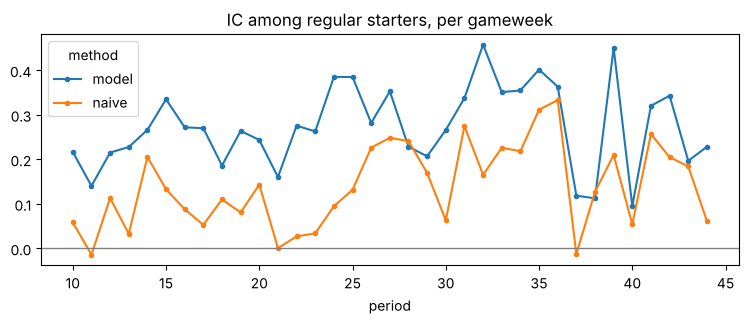

In [3]:
ic = results.pivot(index="period", columns="method", values="ic_starters")
ax = ic.plot(figsize=(9, 3), marker=".")
ax.axhline(0, c="grey", lw=1)
ax.set_title("IC among regular starters, per gameweek")
plt.show()

## 3. Calibration: is a 5-point forecast worth 5 points?

The backtest saves scores but not row-level forecasts, so this section refits the walk-forward on the full panel. It should take a few seconds.

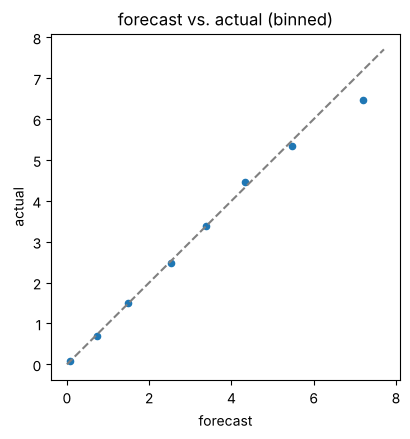

,forecast,actual,n
xpts,,,
"(-inf, 0.5]",0.08,0.09,13268
"(0.5, 1.0]",0.73,0.69,2078
"(1.0, 2.0]",1.48,1.49,3177
"(2.0, 3.0]",2.53,2.48,3492
"(3.0, 4.0]",3.37,3.38,3616
"(4.0, 5.0]",4.33,4.47,490
"(5.0, 6.0]",5.46,5.34,94
"(6.0, inf]",7.21,6.46,82


In [4]:
import numpy as np
from baseline_model import MIN_TRAIN_GWS, fit_predict

panel = add_period(pd.read_csv("../data/player_gw_panel.csv"))
played = panel[panel["total_points"].notna()]
fc = []
for t in sorted(played["period"].unique()):
    if t < MIN_TRAIN_GWS:
        continue
    test = played[(played["period"] == t) & (played["gws_observed"] > 0)].copy()
    test["xpts"] = fit_predict(played[played["period"] < t], test)
    fc.append(test)
fc = pd.concat(fc)

bins = pd.cut(fc["xpts"], [-np.inf, 0.5, 1, 2, 3, 4, 5, 6, np.inf])
calib = fc.groupby(bins, observed=True).agg(forecast=("xpts", "mean"), actual=("total_points", "mean"), n=("xpts", "size"))
ax = calib.plot.scatter("forecast", "actual", figsize=(4.5, 4.5))
lim = [0, calib[["forecast", "actual"]].max().max() + 0.5]
ax.plot(lim, lim, ls="--", c="grey")
ax.set_title("forecast vs. actual (binned)")
plt.show()
calib.round(2)

## 4. What the model leans on

These are standardised ridge coefficients for points per fixture. Many features are strongly correlated with each other (minutes, play rate, start rate), so read them as a group and not one by one: **minutes dominates**, then recent points, then price and fixture difficulty.

In [5]:
coefficients(panel).round(3).to_frame("coef")

,coef
mins_mean_3,1.135
pts_mean_5,0.425
start_rate_5,-0.378
play_rate_5,0.304
price_m,0.251
pts_per_m_5,-0.232
has_history,-0.185
difficulty,-0.143
pos_DEF,0.051
pts_sharpe_5,-0.043


## 5. Upcoming gameweek forecast

In [6]:
pd.read_csv("../data/forecast_next_gw.csv").head(20).round(2)

,element,web_name,position,team,season,round,price_m,difficulty,n_fixtures,start_rate_5,xpts,naive
0,411,Haaland,FWD,15,2026-27,8,15.7,3.0,1,1.0,6.85,8.6
1,426,B.Fernandes,MID,16,2026-27,8,11.8,3.0,1,1.0,4.75,1.6
2,154,Palmer,MID,6,2026-27,8,9.8,2.0,1,1.0,4.69,3.6
3,40,Rogers,MID,6,2026-27,8,8.0,2.0,1,1.0,4.42,5.4
4,12,Saka,MID,1,2026-27,8,9.6,3.0,1,1.0,4.37,3.4
5,427,Mbeumo,MID,16,2026-27,8,7.9,3.0,1,1.0,4.34,5.6
6,4,Gabriel,DEF,1,2026-27,8,7.9,3.0,1,1.0,4.32,4.4
7,13,Rice,MID,1,2026-27,8,7.3,3.0,1,1.0,4.14,5.6
8,106,Thiago,FWD,4,2026-27,8,7.8,2.0,1,1.0,4.09,3.2
9,356,Virgil,DEF,14,2026-27,8,6.4,3.0,1,1.0,3.97,5.2


## Caveats and next steps

- These are **point forecasts only**. The README's next layers add uncertainty: a minutes / rotation-risk model (Layer 2), then predictive distributions for the Monte Carlo simulator (Layer 3).
- Ridge is linear. XGBoost (Layer 1 in the README) has to beat **this** model in the same walk-forward setup to earn its place.
- The forecasts shrink toward the average, e.g. Haaland's 6.9 against his naive 8.6. That is regression to the mean: the model has learned that hot streaks fade.